# Setup

In [1]:
# Import libraries
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import earthkit.data
import regionmask

print("All libraries imported successfully!")

c:\Users\Adam\miniforge3\envs\era5-analysis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All libraries imported successfully!


In [2]:
## API key
# ==========================================
# ENTER YOUR CDS API KEY HERE
# ==========================================
CDS_URL = 'https://cds.climate.copernicus.eu/api'
CDS_API_KEY = '7544a57c-19c7-4770-a33e-5eb47b31c2a6'  # Replace with your actual API key (format: xxxxxxxx-xxxx-xxxx-xxxx-xxxxxxxxxxxx)

# Set as environment variables for earthkit
os.environ['CDSAPI_URL'] = CDS_URL
os.environ['CDSAPI_KEY'] = CDS_API_KEY

In [3]:

import os
import sys
import importlib
import tempfile
from pathlib import Path

# ============================================================
# 1. CDS API credentials
# ============================================================

# Assumes CDS_URL and CDS_API_KEY have already been defined.
os.environ["CDSAPI_URL"] = CDS_URL
os.environ["CDSAPI_KEY"] = CDS_API_KEY

print("=" * 55)
print("ERA5 ENVIRONMENT TEST")
print("=" * 55)

# ============================================================
# 2. Check Python version
# ============================================================

print(f"\nPython version: {sys.version.split()[0]}")
print(f"Python executable: {sys.executable}")

# ============================================================
# 3. Test installed packages
# ============================================================

packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "xarray": "xarray",
    "netCDF4": "netCDF4",
    "cfgrib": "cfgrib",
    "eccodes": "eccodes",
    "dask": "dask",
    "scipy": "scipy",
    "matplotlib": "matplotlib",
    "cartopy": "cartopy",
    "sklearn": "scikit-learn",
    "cdsapi": "cdsapi",
    "earthkit.data": "earthkit-data",
    "regionmask": "regionmask",
    "xeofs": "xeofs",
}

failed = []

print("\nChecking installed packages:\n")

for module, package in packages.items():
    try:
        importlib.import_module(module)
        print(f"  [OK] {package}")
    except Exception as e:
        print(f"  [FAIL] {package}: {e}")
        failed.append(package)

# ============================================================
# 4. Check CDS API configuration
# ============================================================

print("\nChecking CDS API configuration:\n")

url = os.environ.get("CDSAPI_URL")
key = os.environ.get("CDSAPI_KEY")

if url and key:
    print(f"  [OK] CDS API URL: {url}")
    print("  [OK] CDS API key is configured (hidden)")
else:
    print("  [FAIL] CDS API credentials missing")

# ============================================================
# 5. Test Xarray and NumPy
# ============================================================

print("\nTesting Xarray and NumPy:\n")

try:
    import numpy as np
    import xarray as xr

    data = xr.DataArray(
        np.random.default_rng(42).random((10, 20)),
        dims=["latitude", "longitude"],
        coords={
            "latitude": np.linspace(50, 60, 10),
            "longitude": np.linspace(-10, 10, 20),
        },
        name="temperature",
    )

    print(f"  [OK] Created DataArray: {data.shape}")
    print(f"  [OK] Mean value: {data.mean().item():.4f}")

except Exception as e:
    print(f"  [FAIL] Xarray test: {e}")
    failed.append("xarray computation")

# ============================================================
# 6. Test NetCDF writing and reading
# ============================================================

print("\nTesting NetCDF:\n")

try:
    with tempfile.TemporaryDirectory() as tmp:
        path = Path(tmp) / "test.nc"

        data.to_netcdf(path, engine="netcdf4")

        with xr.open_dataarray(path, engine="netcdf4") as loaded:
            np.testing.assert_allclose(
                loaded.values, data.values
            )

    print("  [OK] NetCDF write/read successful")

except Exception as e:
    print(f"  [FAIL] NetCDF test: {e}")
    failed.append("NetCDF read/write")

# ============================================================
# 7. Test CDS API client initialization
# ============================================================

print("\nTesting CDS API client:\n")

try:
    import cdsapi

    client = cdsapi.Client(
        url=os.environ["CDSAPI_URL"],
        key=os.environ["CDSAPI_KEY"],
        quiet=True,
    )

    print("  [OK] CDS API client initialized")
    print("  [INFO] No download attempted yet")

except Exception as e:
    print(f"  [FAIL] CDS API client: {e}")
    failed.append("CDS API client")

# ============================================================
# 8. Summary
# ============================================================

print("\n" + "=" * 55)

if not failed:
    print("SUCCESS: All local environment tests passed!")
else:
    print(f"WARNING: {len(failed)} test(s) failed")
    print("Failed:", ", ".join(failed))

print("=" * 55)


ERA5 ENVIRONMENT TEST

Python version: 3.12.16
Python executable: c:\Users\Adam\miniforge3\envs\era5-analysis\python.exe

Checking installed packages:

  [OK] numpy
  [OK] pandas
  [OK] xarray
  [OK] netCDF4
  [OK] cfgrib
  [OK] eccodes
  [OK] dask
  [OK] scipy
  [OK] matplotlib
  [OK] cartopy
  [OK] scikit-learn
  [OK] cdsapi
  [OK] earthkit-data
  [OK] regionmask
  [OK] xeofs

Checking CDS API configuration:

  [OK] CDS API URL: https://cds.climate.copernicus.eu/api
  [OK] CDS API key is configured (hidden)

Testing Xarray and NumPy:

  [OK] Created DataArray: (10, 20)
  [OK] Mean value: 0.4939

Testing NetCDF:

  [OK] NetCDF write/read successful

Testing CDS API client:

  [OK] CDS API client initialized
  [INFO] No download attempted yet

SUCCESS: All local environment tests passed!


2026-11-16 15:19:08,134 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.


ERA5 END-TO-END ENVIRONMENT TEST

[1/6] Checking CDS API credentials...
[OK] CDS API credentials configured

[2/6] Downloading ERA5 data...


2026-11-16 15:19:09,487 INFO Request ID is 769de1a6-043a-4bed-8e3f-40f70a724f55
2026-11-16 15:19:09,556 INFO status has been updated to accepted
2026-11-16 15:19:31,276 INFO status has been updated to running
2026-11-16 15:19:44,081 INFO status has been updated to successful


[OK] ERA5 download complete
File: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\data\era5_uk_temperature.nc
Size: 28.50 KB

[3/6] Opening ERA5 NetCDF dataset...

Dataset:
<xarray.Dataset> Size: 10kB
Dimensions:     (valid_time: 1, latitude: 41, longitude: 57)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8B 2024-01-01T12:00:00
  * latitude    (latitude) float64 328B 59.0 58.75 58.5 ... 49.5 49.25 49.0
  * longitude   (longitude) float64 456B -11.0 -10.75 -10.5 ... 2.5 2.75 3.0
    number      int64 8B ...
    expver      <U4 16B ...
Data variables:
    t2m         (valid_time, latitude, longitude) float32 9kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-16T15:19 GRIB to CDM+CF via cfgrib-0.9.1...

Vari

c:\Users\Adam\miniforge3\envs\era5-analysis\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
c:\Users\Adam\miniforge3\envs\era5-analysis\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


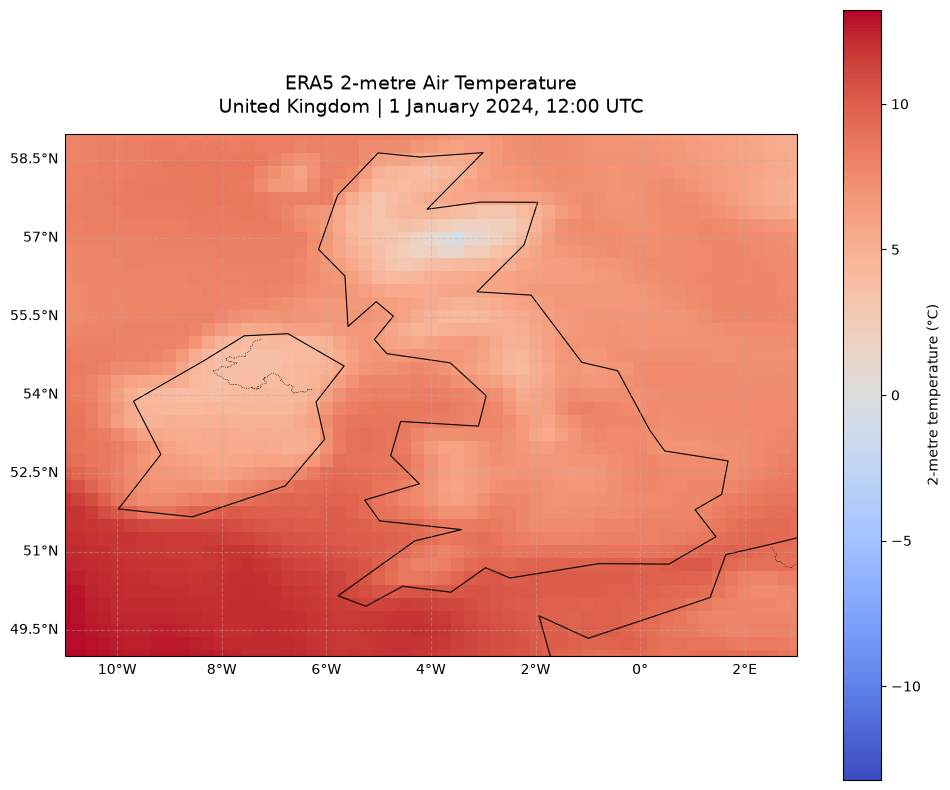

[OK] Map saved: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\data\era5_uk_temperature.png

[6/6] Running final checks...

ERA5 END-TO-END TEST RESULTS
[PASS] CDS API credentials configured
[PASS] ERA5 NetCDF file exists
[PASS] ERA5 NetCDF file is non-empty
[PASS] Temperature variable available
[PASS] Temperature converted to Celsius
[PASS] Temperature values are finite
[PASS] Temperature statistics calculated
[PASS] Temperature map saved
SUCCESS: ERA5 END-TO-END WORKFLOW IS OPERATIONAL!


In [4]:
import os
from pathlib import Path

import cdsapi
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ============================================================
# ERA5 END-TO-END ENVIRONMENT TEST
# ============================================================

print("=" * 60)
print("ERA5 END-TO-END ENVIRONMENT TEST")
print("=" * 60)

# ============================================================
# 1. CDS API CREDENTIALS
# ============================================================

# Assumes CDS_URL and CDS_API_KEY are already defined.
# Do not print or commit your API key.

os.environ["CDSAPI_URL"] = CDS_URL
os.environ["CDSAPI_KEY"] = CDS_API_KEY

print("\n[1/6] Checking CDS API credentials...")

assert os.environ.get("CDSAPI_URL"), "Missing CDS API URL"
assert os.environ.get("CDSAPI_KEY"), "Missing CDS API key"

print("[OK] CDS API credentials configured")

# ============================================================
# 2. DOWNLOAD ERA5 DATA
# ============================================================

print("\n[2/6] Downloading ERA5 data...")

data_dir = Path("data")
data_dir.mkdir(parents=True, exist_ok=True)

output_file = data_dir / "era5_uk_temperature.nc"

client = cdsapi.Client(
    url=os.environ["CDSAPI_URL"],
    key=os.environ["CDSAPI_KEY"]
)

if not output_file.exists():

    client.retrieve(
        "reanalysis-era5-single-levels",
        {
            "product_type": ["reanalysis"],
            "variable": ["2m_temperature"],
            "year": ["2024"],
            "month": ["01"],
            "day": ["01"],
            "time": ["12:00"],
            "data_format": "netcdf",
            "download_format": "unarchived",
            "area": [59, -11, 49, 3],
        },
        str(output_file.resolve()),
    )

    print("[OK] ERA5 download complete")

else:
    print("[OK] Existing ERA5 file found")

print(f"File: {output_file.resolve()}")
print(f"Size: {output_file.stat().st_size / 1024:.2f} KB")

# ============================================================
# 3. OPEN AND INSPECT DATASET
# ============================================================

print("\n[3/6] Opening ERA5 NetCDF dataset...")

ds = xr.open_dataset(output_file)

print("\nDataset:")
print(ds)

print("\nVariables:", list(ds.data_vars))
print("Dimensions:", dict(ds.sizes))
print("Coordinates:", list(ds.coords))

assert "t2m" in ds.data_vars, "Temperature variable t2m missing"

print("\n[OK] NetCDF dataset opened successfully")

# ============================================================
# 4. TEMPERATURE ANALYSIS
# ============================================================

print("\n[4/6] Analysing ERA5 temperature...")

# Convert Kelvin to Celsius
temperature_c = (ds["t2m"] - 273.15).squeeze()

temperature_c.attrs["units"] = "degC"
temperature_c.attrs["long_name"] = "2-metre air temperature"

# Calculate statistics
t_min = temperature_c.min().item()
t_max = temperature_c.max().item()
t_mean = temperature_c.mean().item()
t_std = temperature_c.std().item()

print("\nTemperature statistics:")
print("-" * 40)
print(f"Minimum:            {t_min:.2f} °C")
print(f"Maximum:            {t_max:.2f} °C")
print(f"Mean:               {t_mean:.2f} °C")
print(f"Standard deviation: {t_std:.2f} °C")

assert np.isfinite(temperature_c.values).all(), (
    "Temperature contains NaN or infinite values"
)

print("\n[OK] Temperature calculations successful")

# ============================================================
# 5. VISUALISE TEMPERATURE WITH CARTOPY
# ============================================================

print("\n[5/6] Generating ERA5 temperature map...")

fig = plt.figure(figsize=(10, 8))

ax = plt.axes(
    projection=ccrs.PlateCarree()
)

# Plot temperature field
temperature_c.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="coolwarm",
    cbar_kwargs={
        "label": "2-metre temperature (°C)"
    }
)

# Geographic features
ax.coastlines(
    resolution="110m",
    linewidth=0.8
)

ax.add_feature(
    cfeature.BORDERS,
    linestyle=":",
    linewidth=0.5
)

# Map extent
ax.set_extent(
    [-11, 3, 49, 59],
    crs=ccrs.PlateCarree()
)

# Gridlines
ax.gridlines(
    draw_labels={"bottom": "x", "left": "y"},
    linestyle="--",
    alpha=0.4
)

# Title
ax.set_title(
    "ERA5 2-metre Air Temperature\n"
    "United Kingdom | 1 January 2024, 12:00 UTC",
    fontsize=14,
    pad=15
)

plt.tight_layout()

# Save figure
figure_file = data_dir / "era5_uk_temperature.png"

plt.savefig(
    figure_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(f"[OK] Map saved: {figure_file.resolve()}")

# ============================================================
# 6. FINAL VERIFICATION
# ============================================================

print("\n[6/6] Running final checks...")

checks = {
    "CDS API credentials configured":
        bool(os.environ.get("CDSAPI_URL")) and
        bool(os.environ.get("CDSAPI_KEY")),

    "ERA5 NetCDF file exists":
        output_file.exists(),

    "ERA5 NetCDF file is non-empty":
        output_file.stat().st_size > 0,

    "Temperature variable available":
        "t2m" in ds.data_vars,

    "Temperature converted to Celsius":
        temperature_c.attrs.get("units") == "degC",

    "Temperature values are finite":
        bool(np.isfinite(temperature_c.values).all()),

    "Temperature statistics calculated":
        bool(np.isfinite([t_min, t_max, t_mean, t_std]).all()),

    "Temperature map saved":
        figure_file.exists(),
}

print("\n" + "=" * 60)
print("ERA5 END-TO-END TEST RESULTS")
print("=" * 60)

for name, passed in checks.items():
    status = "[PASS]" if passed else "[FAIL]"
    print(f"{status} {name}")

print("=" * 60)

if all(checks.values()):
    print("SUCCESS: ERA5 END-TO-END WORKFLOW IS OPERATIONAL!")
else:
    print("WARNING: Some tests failed.")

print("=" * 60)

# Close dataset
ds.close()